# 08　北海道の集合差・送電上限の意味と、4月価格の記述的な接続

旧試行・全17供給条件・固定PV/風力/原子力を保持します。新しい企業除去条件や最終baselineは作りません。今回の図は価格との記述的な接続であり、因果効果・企業不可欠性・売り渋りの認定ではありません。

読む順：①北海道の3設備 → ②送電の原行 → ③倍率と価格 → ④17条件一致区分と価格 → ⑤需要・純需要・時間帯。詳細は `reports/24_april_price_connection/README.md` です。

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "data/interim/occto/april_price_connection/20261027_price_v3"
REPORT = ROOT / "reports/24_april_price_connection"
QA = REPORT / "qa"


def show(name):
    display(Image(filename=str(REPORT / "figures" / (name + ".png"))))


print("価格の基本観測: 9地域法人対×1,440＝12,960")
print("17供給条件×両送電の440,640行は、同じ価格の反復です。")

価格の基本観測: 9地域法人対×1,440＝12,960
17供給条件×両送電の440,640行は、同じ価格の反復です。


## 1．北海道462 MWと250 MWの違い

苫小牧共同3Gの250 MWは両方で採用。室蘭中央5号100・釧路1号112 MWは対応と容量が分かっていても、元燃種が空欄で固定PV/風力との非重複が保留のため今回の調整側集合に入りません。停止・企業除去・期間欠損による差ではありません。

旧散布図の横軸は容量−平均実績出力、新試行は実績を再控除しない上限という指標の違いもあります。2設備を自動復帰していません。

In [2]:
assets = pd.read_csv(QA / "hokkaido_supply_set_reconciliation.csv", keep_default_na=False)
display(
    assets[
        [
            "plant_name",
            "unit_name",
            "raw_fuel",
            "business_name",
            "scatter_capacity_mw",
            "trial_upper_at_example_mw",
            "limited_scope_status",
            "mapping_status",
            "april_observed_cells",
        ]
    ].rename(
        columns={
            "plant_name": "発電所",
            "unit_name": "ユニット",
            "raw_fuel": "元燃種",
            "scatter_capacity_mw": "旧参照容量MW",
            "trial_upper_at_example_mw": "今回代表時刻の上限MW",
        }
    )
)

,発電所,ユニット,元燃種,business_name,旧参照容量MW,今回代表時刻の上限MW,limited_scope_status,mapping_status,april_observed_cells
0,北海道ﾊﾟﾜｰｴﾝｼﾞﾆｱﾘﾝｸﾞ株式会社 苫小牧共同火力発電所3G,単独,火力（石油）,北海道パワーエンジニアリング株式会社,250,250.000000,candidate_known_reference_subset,use_diagnostic,1440
1,日本製鉄（株）室蘭中央発電所 第5号発電設備,室蘭中央5号,,日本製鉄株式会社,100,,held_fuel_scope_unresolved,use_diagnostic,1440
2,釧路火力発電所,1,,株式会社釧路火力発電所,112,,held_fuel_scope_unresolved,use_diagnostic,1440


## 2．送電上限の原行を確認する

`A=C−M−W−P`は、計画潮流Pを前提にした追加の余地。旧モデルは`L/U=C−M−W=A+P`を純移送の再配分包絡とする**条件付きシナリオ**です。保存M/Wを固定し、緊急時のマージン利用・既存利用権・実際の全物理上限を再現しません。

北本の逆方向は−900−(−663)−0＝−237。東北→北海道の表示237 MWは下限の向きを表し、900 MWそのものでも全系列の絶対値化でもありません。Pが0でAと包絡の数字が同じでも、意味が同じとはしません。

In [3]:
trace = pd.read_csv(QA / "representative_network_trace.csv", dtype=str, keep_default_na=False)
display(
    trace[
        [
            "link_name_raw",
            "direction_raw",
            "source_row",
            "運用容量",
            "マージン",
            "広域調整枠",
            "計画潮流",
            "空容量",
            "reviewed_signed_model_bound_mw",
            "対象断面",
            "策定日",
            "策定／更新後",
        ]
    ]
)
display(
    trace[
        [
            "source_file",
            "source_record_id",
            "timestamp_start",
            "timestamp_end",
            "row_updated_at",
            "source_acquired_at",
        ]
    ]
)
display(pd.read_csv(QA / "network_arithmetic_check.csv"))

,link_name_raw,direction_raw,source_row,運用容量,マージン,広域調整枠,計画潮流,空容量,reviewed_signed_model_bound_mw,対象断面,策定日,策定／更新後
0,北海道・本州間電力連系設備,順方向,2,700,20,0,0,680,680.000000,翌々日,20250330,策定
1,北海道・本州間電力連系設備,逆方向,3,-900,-663,0,0,-237,-237.000000,翌々日,20250330,策定
2,相馬双葉幹線,順方向,674,3860,0,0,0,3860,3860.000000,翌々日,20250330,策定
3,相馬双葉幹線,逆方向,675,-2360,0,0,0,-2360,-2360.000000,翌々日,20250330,策定
4,周波数変換設備,順方向,1346,1350,600,0,0,750,750.000000,翌々日,20250330,策定
5,周波数変換設備,逆方向,1347,-1350,-600,0,0,-750,-750.000000,翌々日,20250330,策定
6,三重東近江線,順方向,2018,950,0,0,0,950,950.000000,翌々日,20250330,策定
7,三重東近江線,逆方向,2019,-2000,0,0,0,-2000,-2000.000000,翌々日,20250330,策定
8,南福光連系所・南福光変電所の連系設備,順方向,2690,300,0,0,0,300,300.000000,翌々日,20250330,策定
9,南福光連系所・南福光変電所の連系設備,逆方向,2691,-300,0,0,0,-300,-300.000000,翌々日,20250330,策定


,source_file,source_record_id,timestamp_start,timestamp_end,row_updated_at,source_acquired_at
0,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:08+09:00,2026-10-14T22:06:07+09:00
1,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:08+09:00,2026-10-14T22:06:07+09:00
2,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:08+09:00,2026-10-14T22:06:07+09:00
3,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:08+09:00,2026-10-14T22:06:07+09:00
4,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:09+09:00,2026-10-14T22:06:07+09:00
5,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:09+09:00,2026-10-14T22:06:07+09:00
6,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:08+09:00,2026-10-14T22:06:07+09:00
7,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:08+09:00,2026-10-14T22:06:07+09:00
8,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:09+09:00,2026-10-14T22:06:07+09:00
9,data/raw/occto/system_interconnector_capacity/...,ed112698d19e6c265c476e2f831f679830988fdb26e413...,2025-04-01 00:00:00+09:00,2025-04-01 00:30:00+09:00,2025-03-30 15:00:09+09:00,2026-10-14T22:06:07+09:00


,rows,available_identity_matches,planned_nonzero,meaning_verified_by_zero_flow,model_bounds_changed
0,31680,31680,0,False,False


## 3．図A：地域別純需要倍率と当該地域価格

説明用条件は停止控除なし・送電制約あり、1点＝30分です。未算定は0にせず別表へ残します。全範囲と0〜2倍表示を分け、極端値を削除しません。需要や時間帯を揃えた比較ではありません。

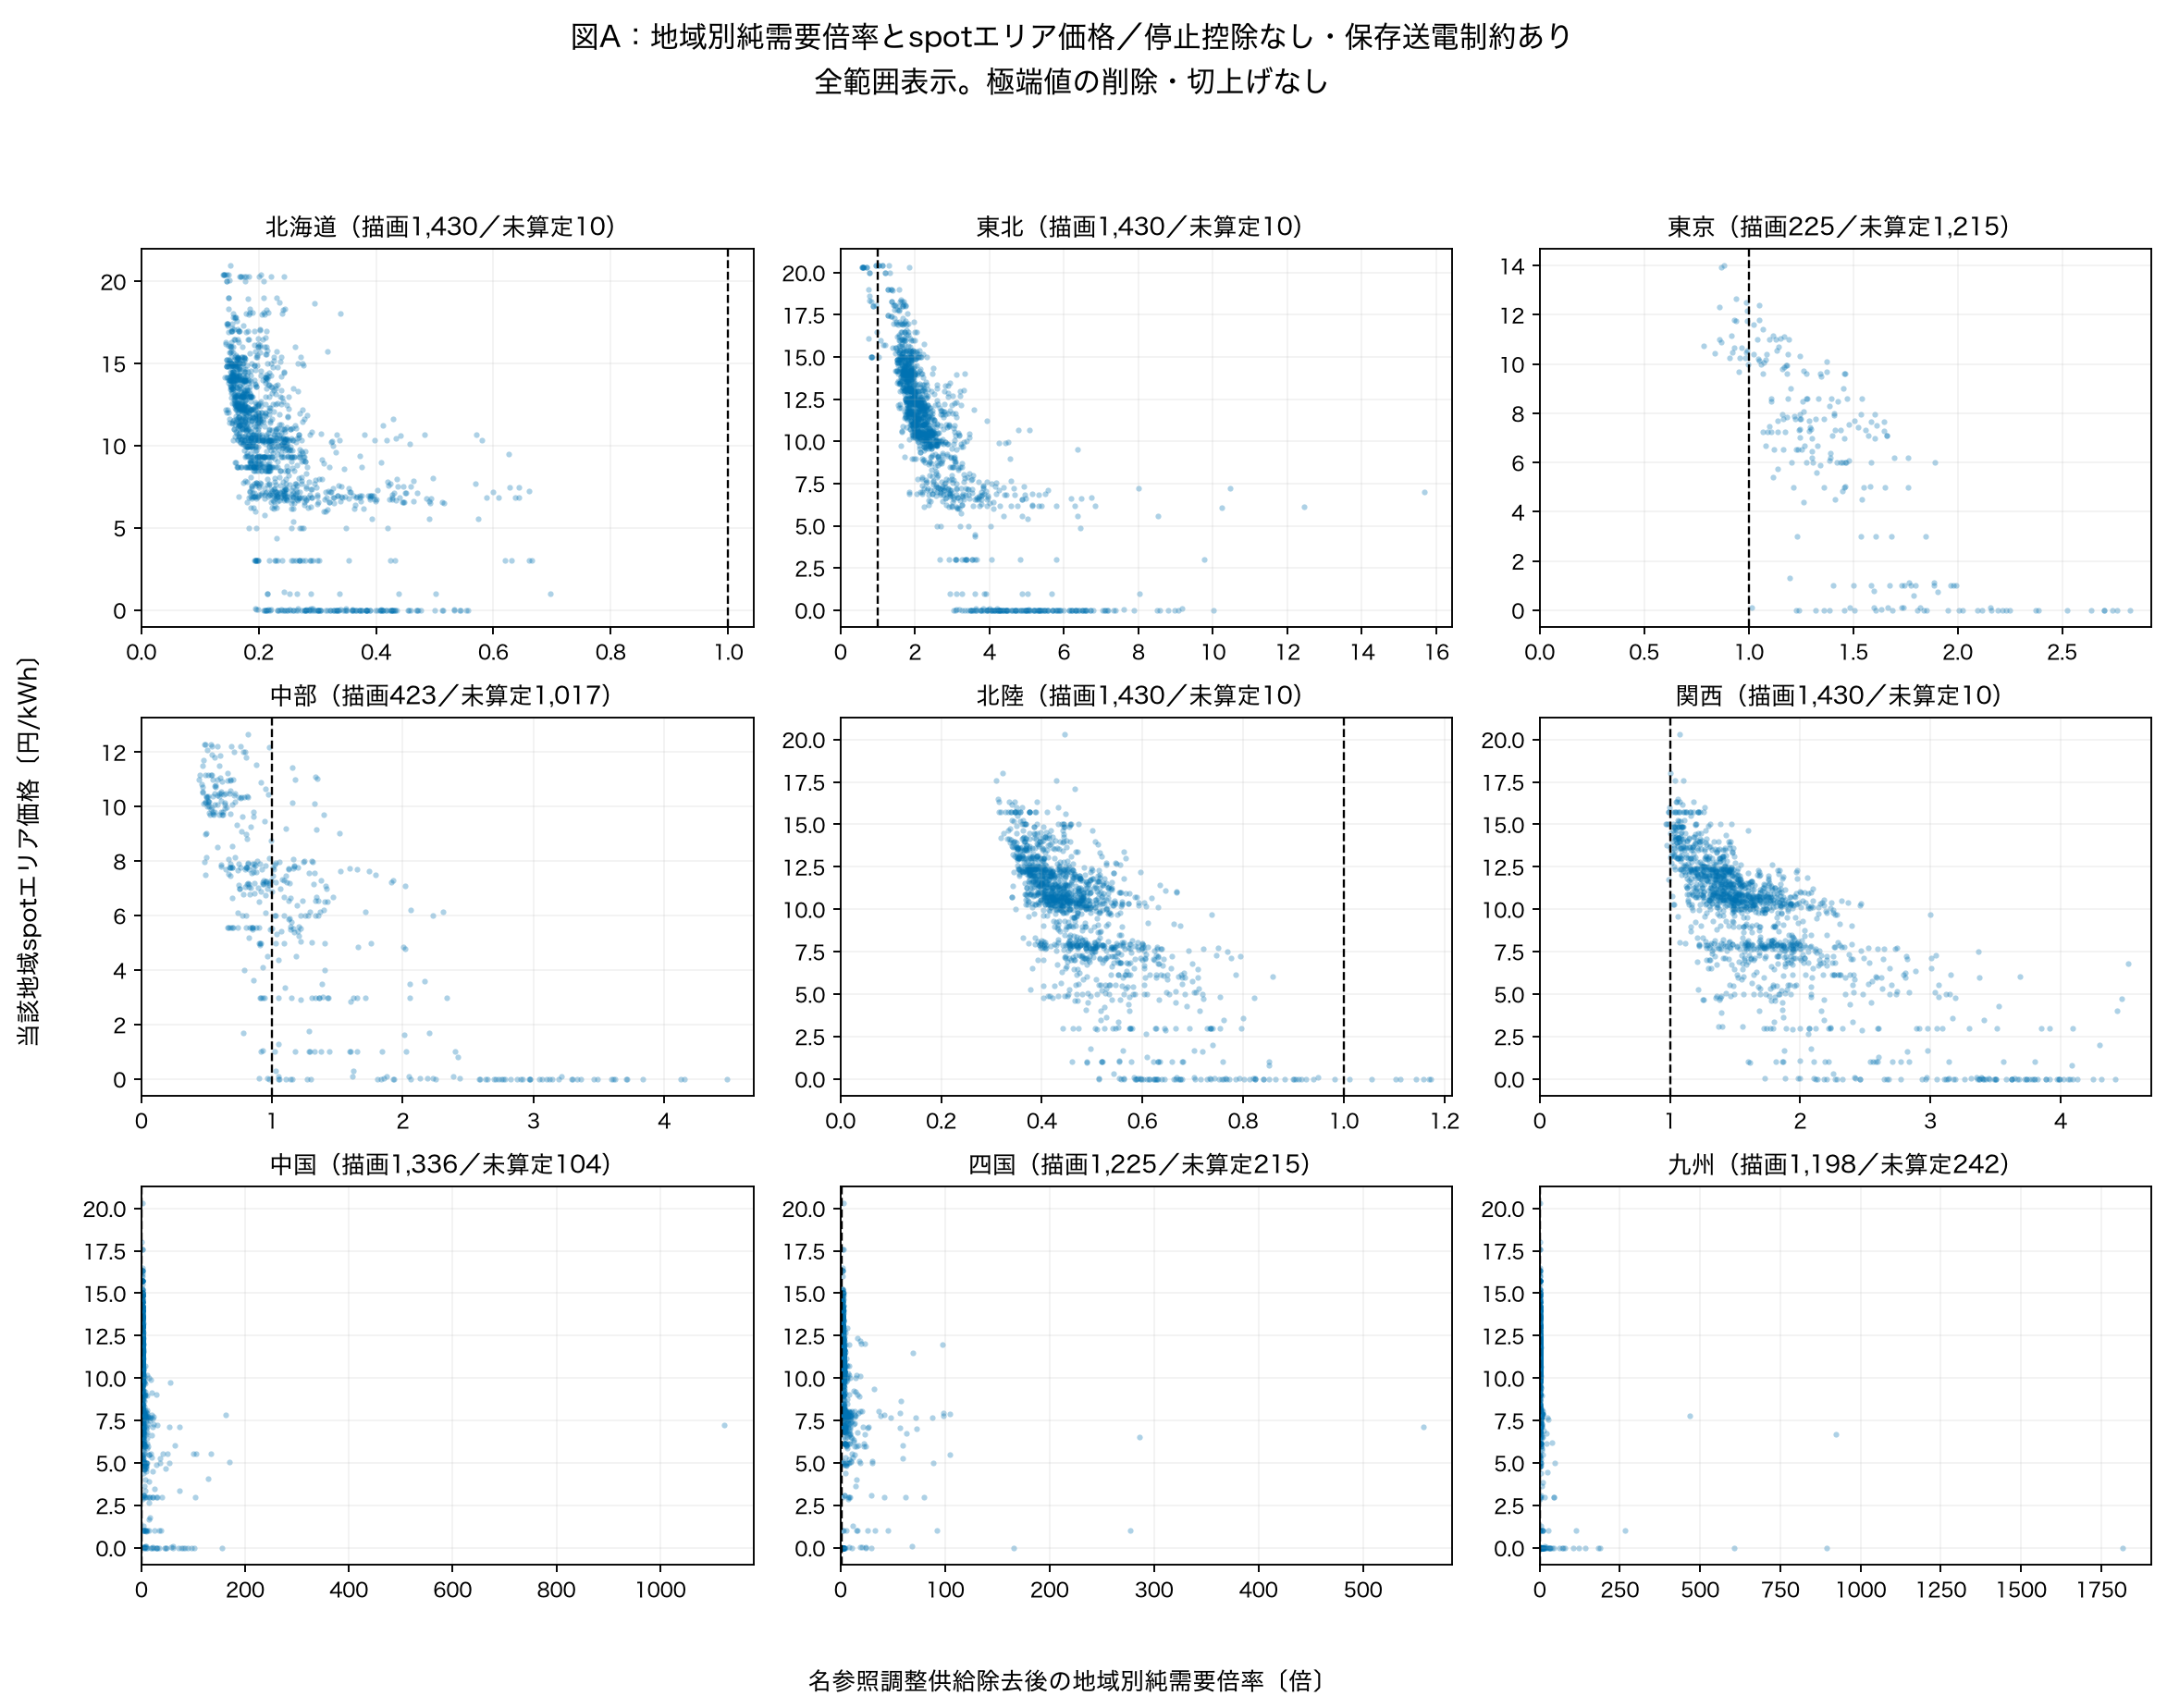

,target_area,all_times,valid,unplottable,above_zoom_2,max_multiplier
0,北海道,1440,1430,10,0,0.696357
1,東北,1440,1430,10,874,15.679028
2,東京,1440,225,1215,19,2.826623
3,中部,1440,423,1017,62,4.479756
4,北陸,1440,1430,10,0,1.173096
5,関西,1440,1430,10,267,4.521881
6,中国,1440,1336,104,561,1123.675714
7,四国,1440,1225,215,1040,557.833333
8,九州,1440,1198,242,146,1817.000000


,target_area,status,count
0,中国,all_firms_infeasible,2
1,中国,nonpositive_target_net,102
2,中国,valid,1336
3,中部,all_firms_infeasible,10
4,中部,removed_other_regions_infeasible,1007
5,中部,valid,423
6,九州,nonpositive_target_net,242
7,九州,valid,1198
8,北海道,all_firms_infeasible,10
9,北海道,valid,1430


In [4]:
show("01_multiplier_price_full")
display(pd.read_csv(QA / "scatter_display_windows.csv"))
display(pd.read_csv(QA / "scatter_all_status_counts.csv"))

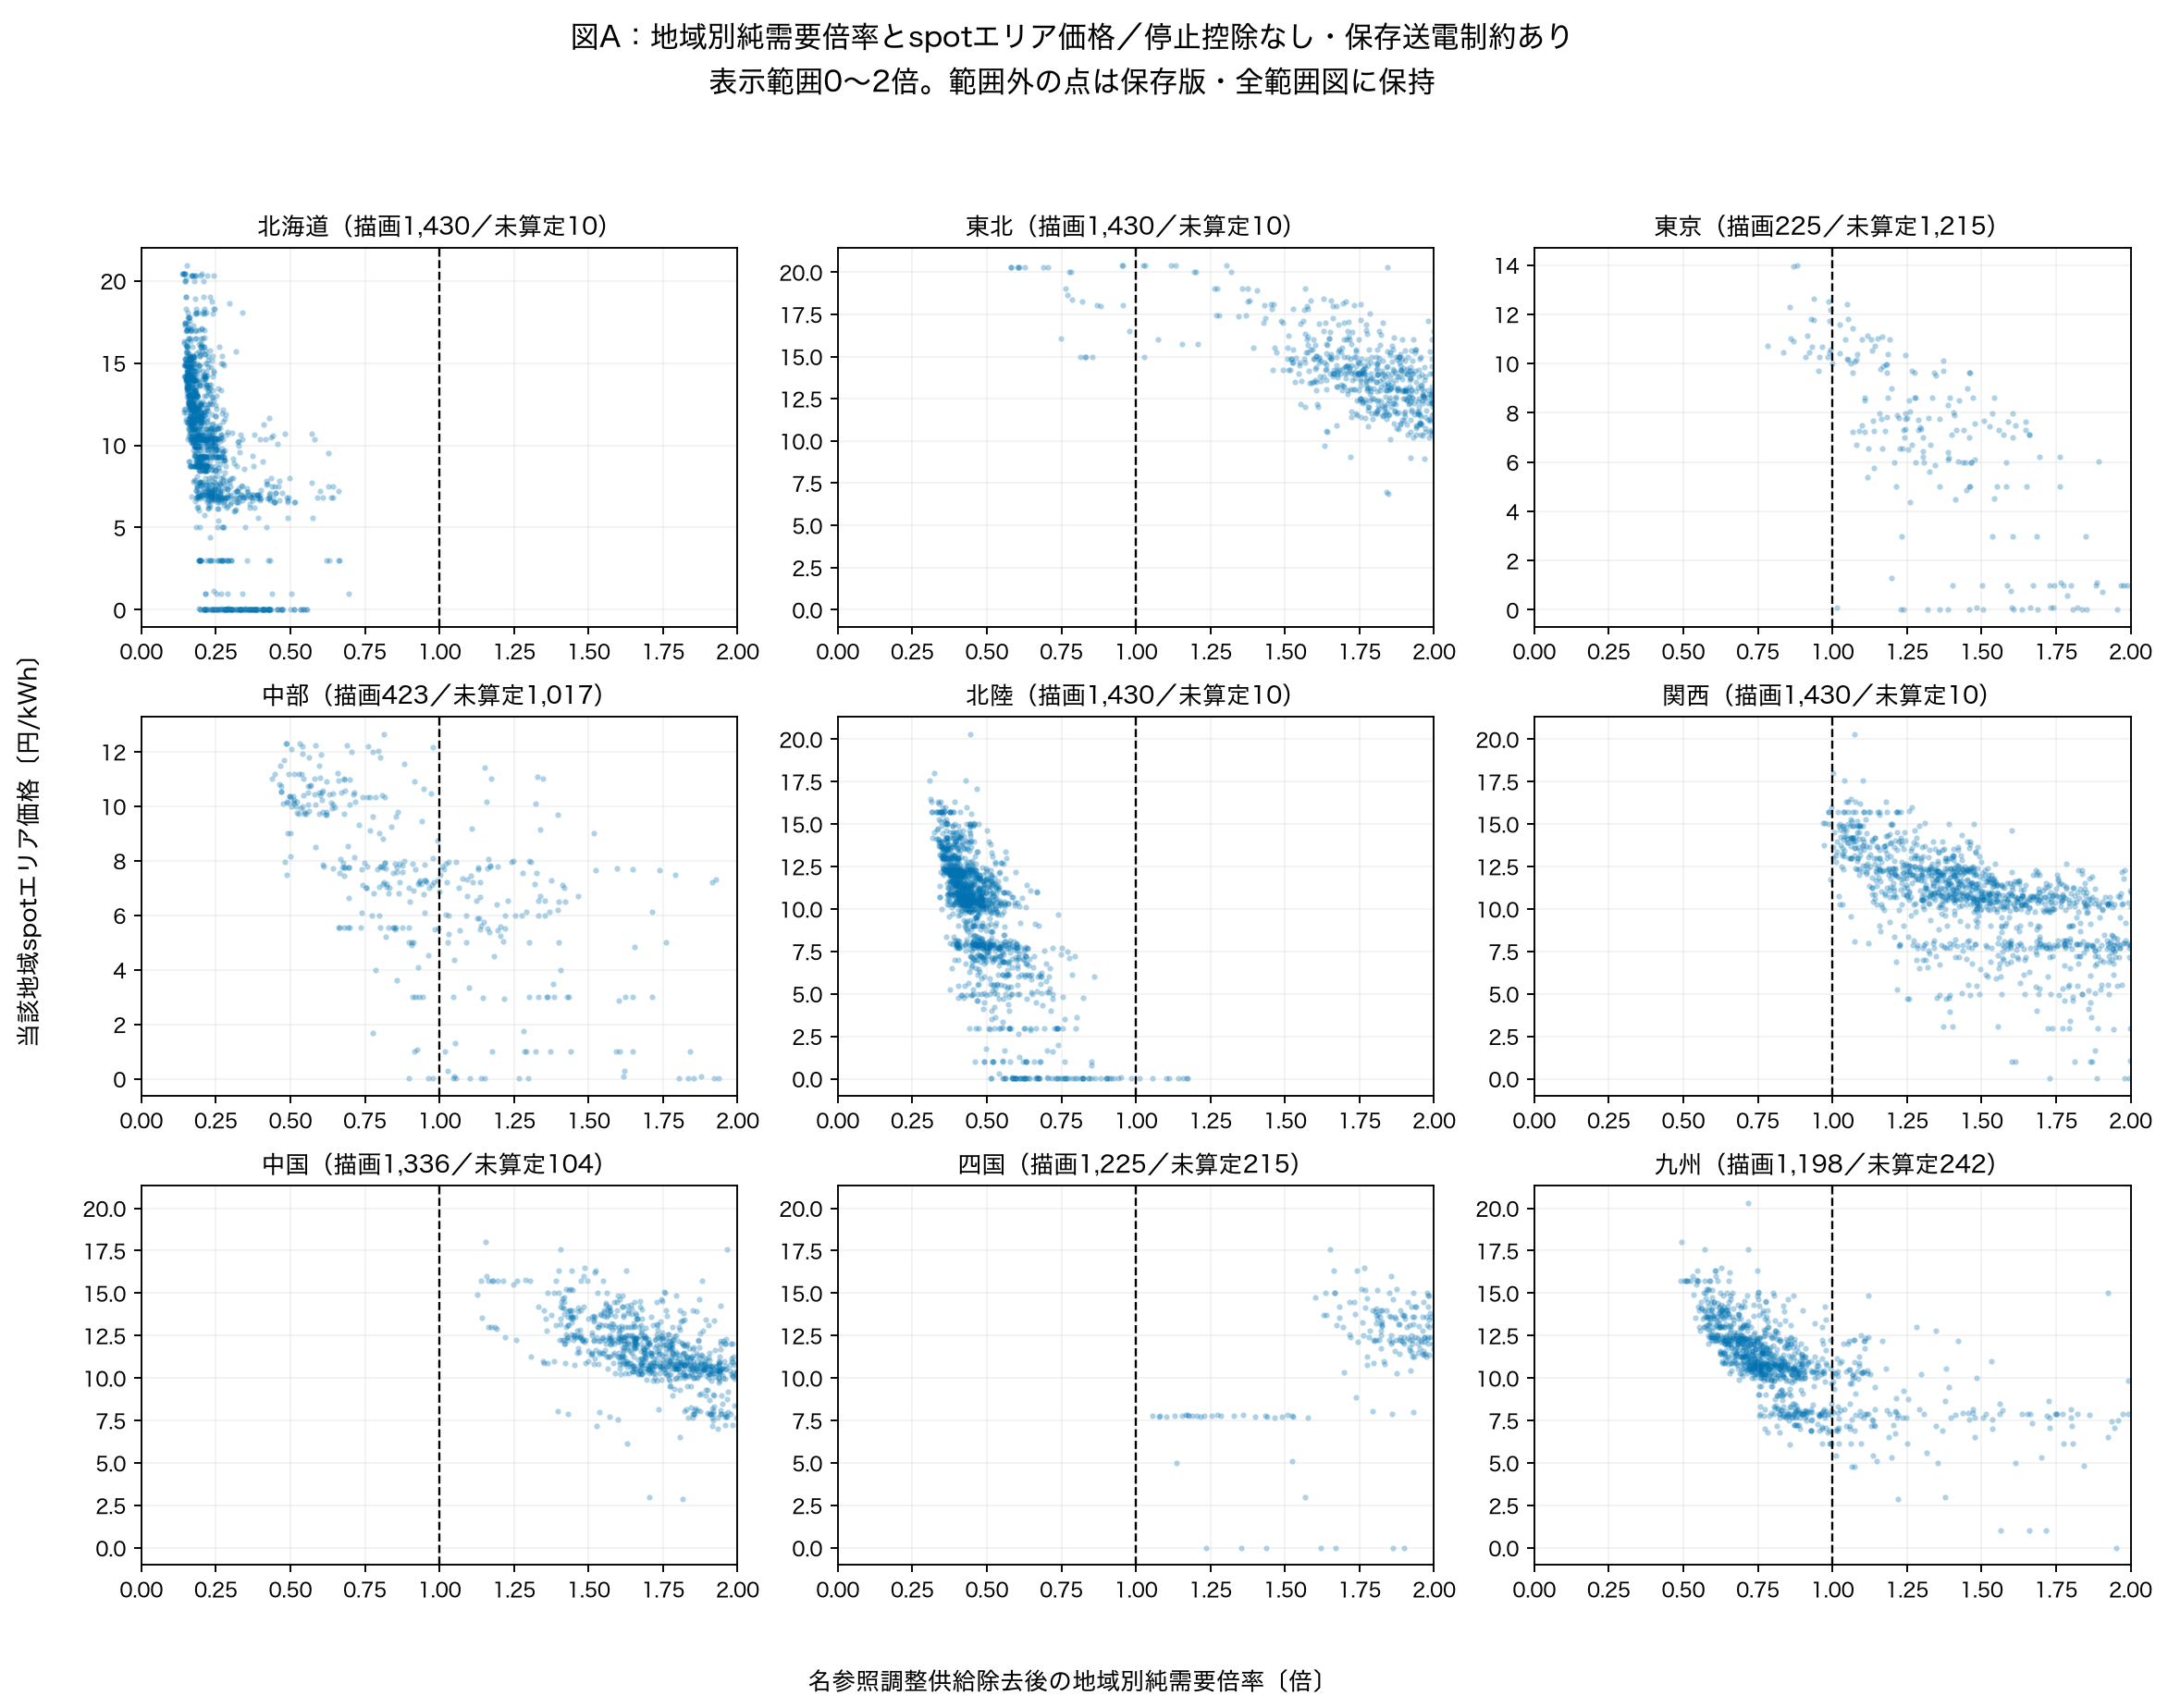

,target_area,rule,example_status,delivery_date,period,area_price,lambda_removed,observed_demand_mw,observed_net_demand_mw
0,北海道,有効・倍率1未満の最小価格（同値は最初）,observed,2025-04-09,25.0,0.01,0.347124,3519.0,1704.0
1,北海道,有効・倍率1以上の最大価格（同値は最初）,該当なし,NaN,NaN,NaN,NaN,NaN,NaN
2,東北,有効・倍率1未満の最小価格（同値は最初）,observed,2025-04-01,21.0,15.00,0.813153,11205.0,8110.0
3,東北,有効・倍率1以上の最大価格（同値は最初）,observed,2025-04-03,19.0,20.42,1.303952,10913.0,8293.0
4,東京,有効・倍率1未満の最小価格（同値は最初）,observed,2025-04-19,32.0,9.70,0.951965,27328.0,20481.0
5,東京,有効・倍率1以上の最大価格（同値は最初）,observed,2025-04-04,27.0,12.40,1.049442,33276.0,19623.0
6,中部,有効・倍率1未満の最小価格（同値は最初）,observed,2025-04-17,28.0,0.01,0.978881,15682.0,7434.0
7,中部,有効・倍率1以上の最大価格（同値は最初）,observed,2025-04-28,20.0,11.42,1.152127,11956.0,6534.0
8,北陸,有効・倍率1未満の最小価格（同値は最初）,observed,2025-04-06,30.0,0.01,0.678102,2274.0,1749.0
9,北陸,有効・倍率1以上の最大価格（同値は最初）,observed,2025-04-27,20.0,0.01,1.056100,2281.0,1123.0


In [5]:
show("02_multiplier_price_near_one")
display(pd.read_csv(QA / "descriptive_extreme_examples.csv"))

## 4．図B：17条件の判定一致区分と価格

図Bは全時刻を使い、図Aで倍率を計算できない純需要非正も含みます。北海道の成立一致群は該当なしで、成立群との価格差を作りません。JERAは1法人の同時成立結果を、異なる東京/中部価格へ接続しています。

九州の成立一致334コマのうち226は純需要非正。純需要中央値は成立一致−339 MW／不成立一致4,940 MWです。価格中央値0.01円／10.84円の差を、企業除去による価格効果と解釈することはできません。

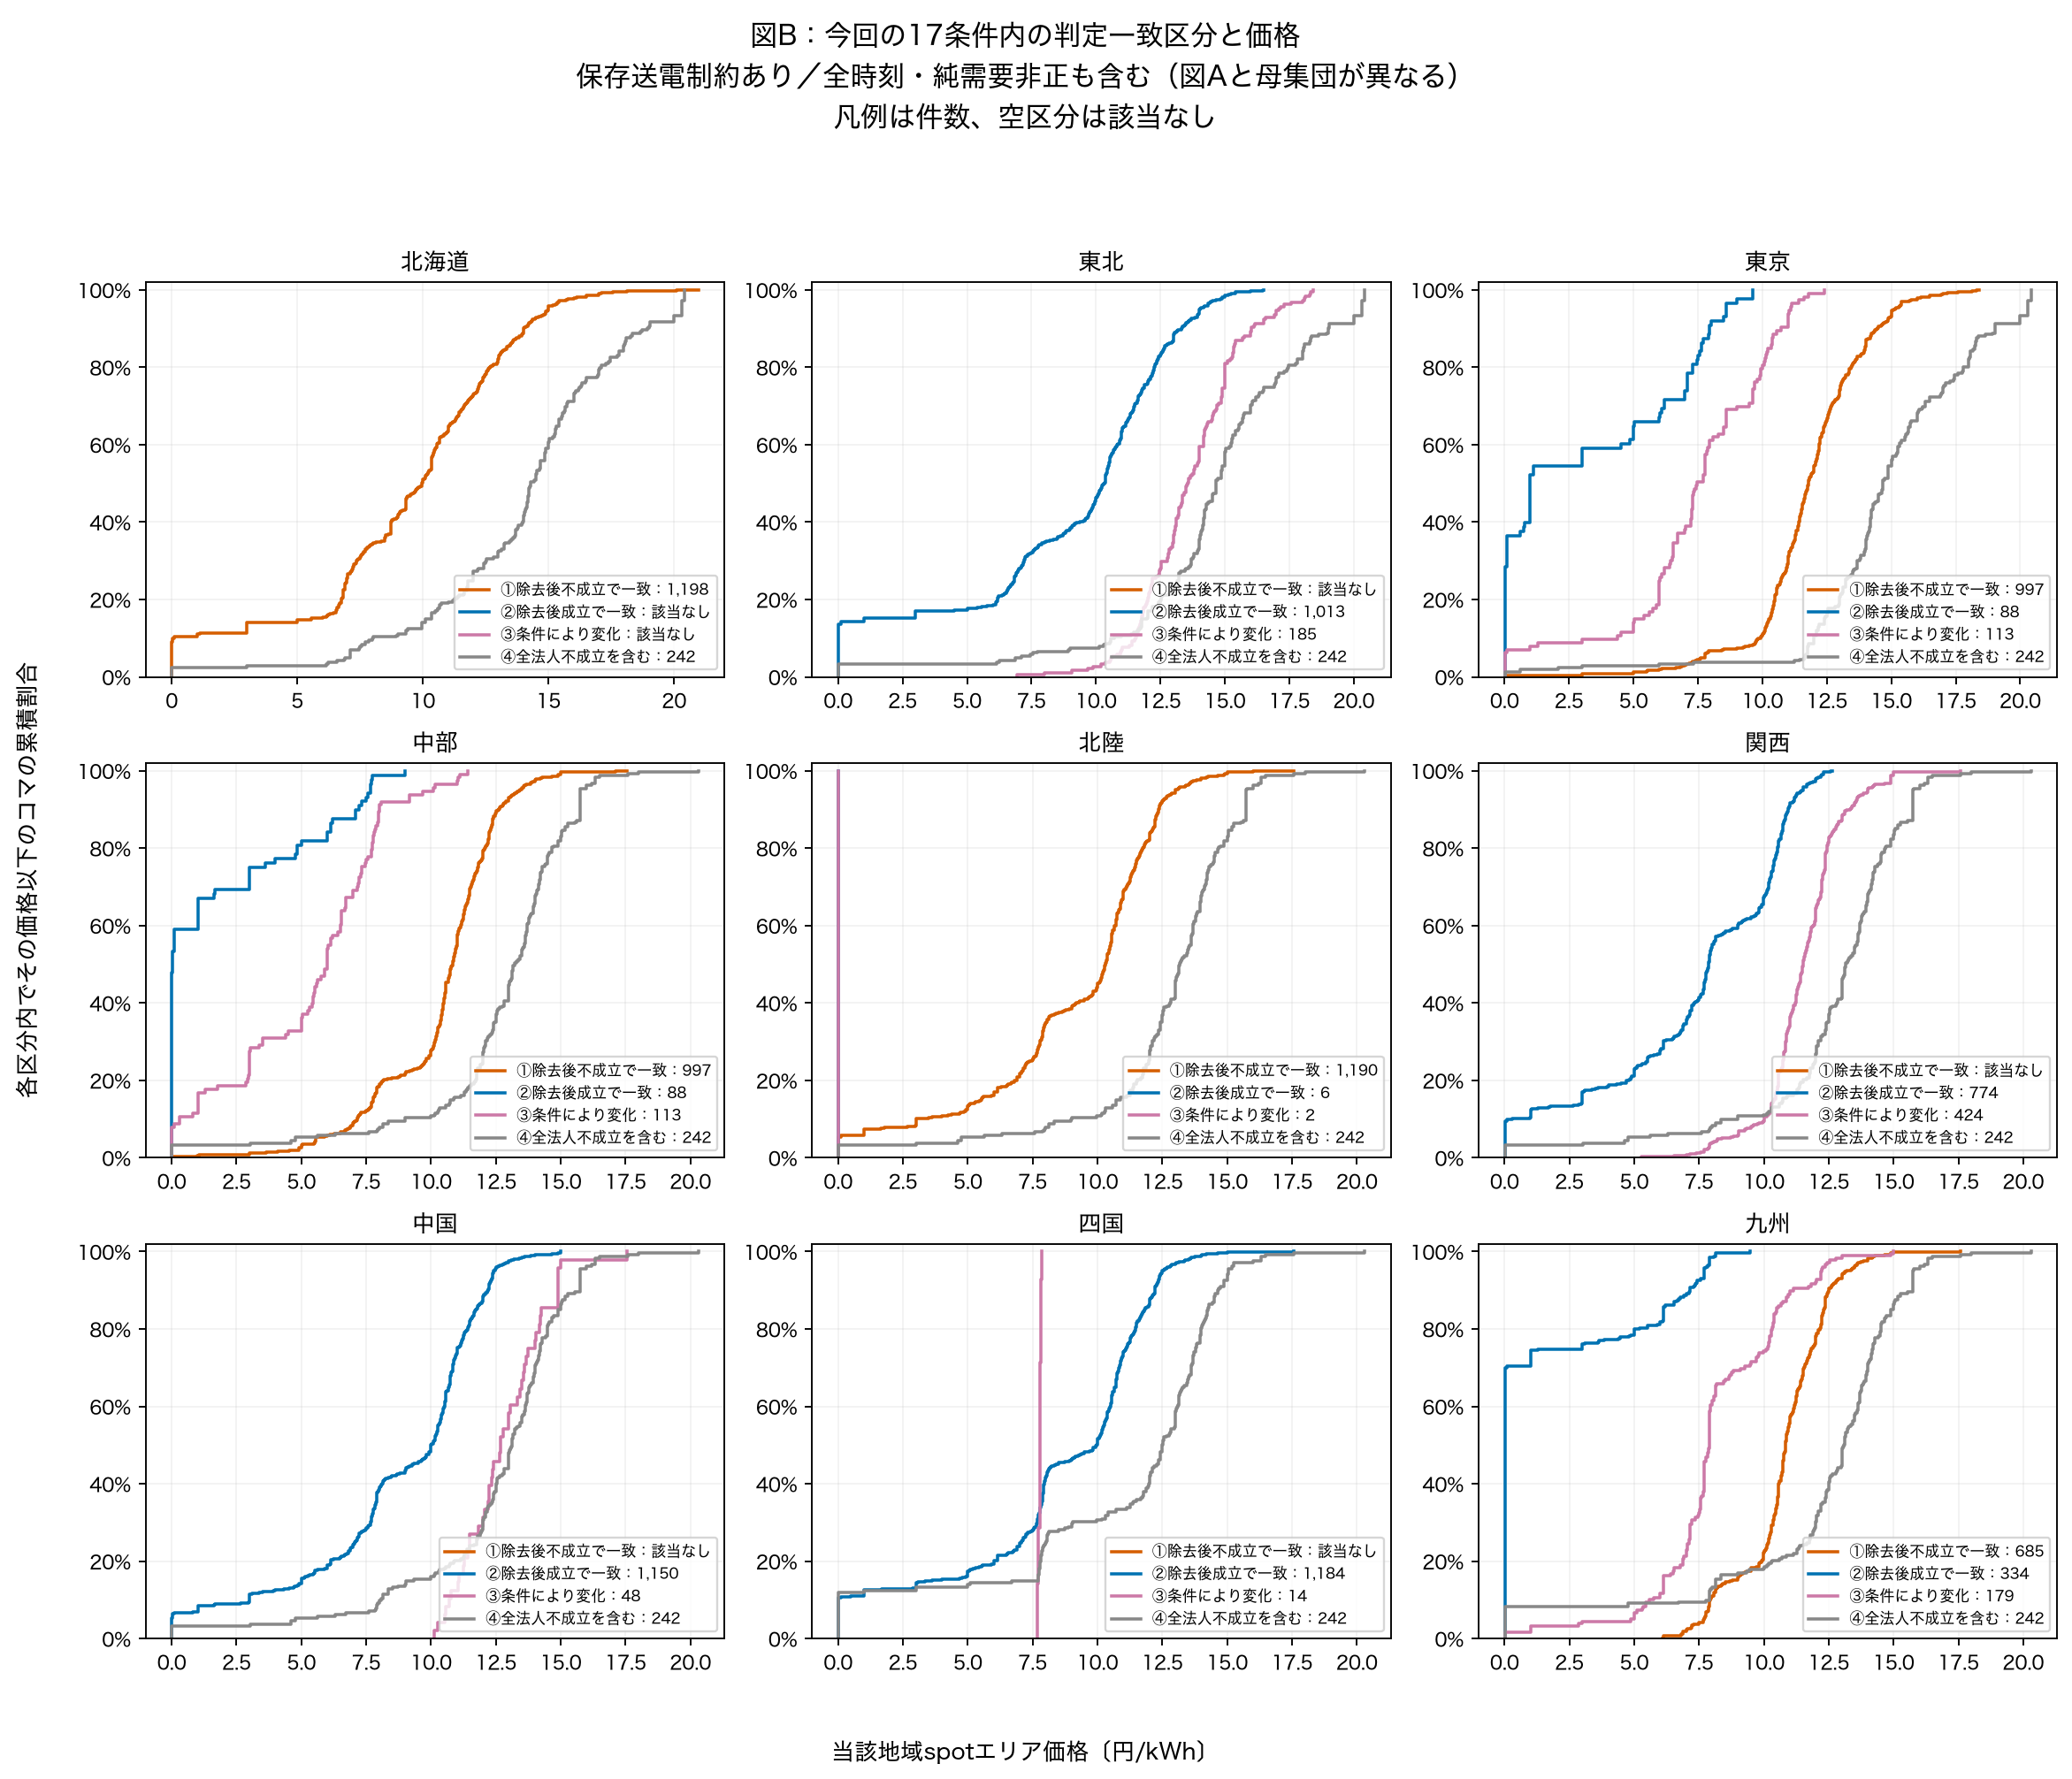

,地域,17条件の区分,variable,件数,最小,25%点,中央値,75%点,最大
0,北海道,all17_base_feasible_removed_infeasible,area_price,1198,0.01,6.9700,9.940,12.2275,20.96
4,北海道,all17_base_feasible_removed_feasible,area_price,0,NaN,NaN,NaN,NaN,NaN
8,北海道,removed_varies_among_baseline_feasible,area_price,0,NaN,NaN,NaN,NaN,NaN
12,北海道,baseline_scope_differs,area_price,242,0.01,12.0000,14.290,16.2850,20.42
16,北海道,other_held,area_price,0,NaN,NaN,NaN,NaN,NaN
20,東北,all17_base_feasible_removed_infeasible,area_price,0,NaN,NaN,NaN,NaN,NaN
24,東北,all17_base_feasible_removed_feasible,area_price,1013,0.01,6.8300,10.330,11.8900,16.49
28,東北,removed_varies_among_baseline_feasible,area_price,185,6.93,12.2000,13.560,15.0000,18.42
32,東北,baseline_scope_differs,area_price,242,0.01,13.2200,14.670,16.8050,20.42
36,東北,other_held,area_price,0,NaN,NaN,NaN,NaN,NaN


,target_area,consistency_state,count,net_nonpositive
0,中国,all17_base_feasible_removed_feasible,1150,94
1,中国,baseline_scope_differs,242,8
2,中国,removed_varies_among_baseline_feasible,48,0
3,中部,all17_base_feasible_removed_feasible,88,0
4,中部,all17_base_feasible_removed_infeasible,997,0
5,中部,baseline_scope_differs,242,0
6,中部,removed_varies_among_baseline_feasible,113,0
7,九州,all17_base_feasible_removed_feasible,334,226
8,九州,all17_base_feasible_removed_infeasible,685,0
9,九州,baseline_scope_differs,242,16


In [6]:
show("03_consistency_price_distribution")
summary = pd.read_csv(QA / "state_price_and_covariate_distribution.csv")
prices = summary[summary.variable.eq("area_price")]
display(
    prices.rename(
        columns={
            "target_area": "地域",
            "consistency_state": "17条件の区分",
            "count": "件数",
            "minimum": "最小",
            "q25": "25%点",
            "median": "中央値",
            "q75": "75%点",
            "maximum": "最大",
        }
    )
)
display(pd.read_csv(QA / "state_nonpositive_net_counts.csv"))

## 5．実績需要・純需要・時間帯も確認する

時刻区分は開始時刻0〜23時という固定区分。事後的な需要閾値・高価格閾値や回帰・有意差検定を使っていません。全国共通system price・感応度基準は別系列で保持し、FY2025の2,271時刻不一致を修正していません。

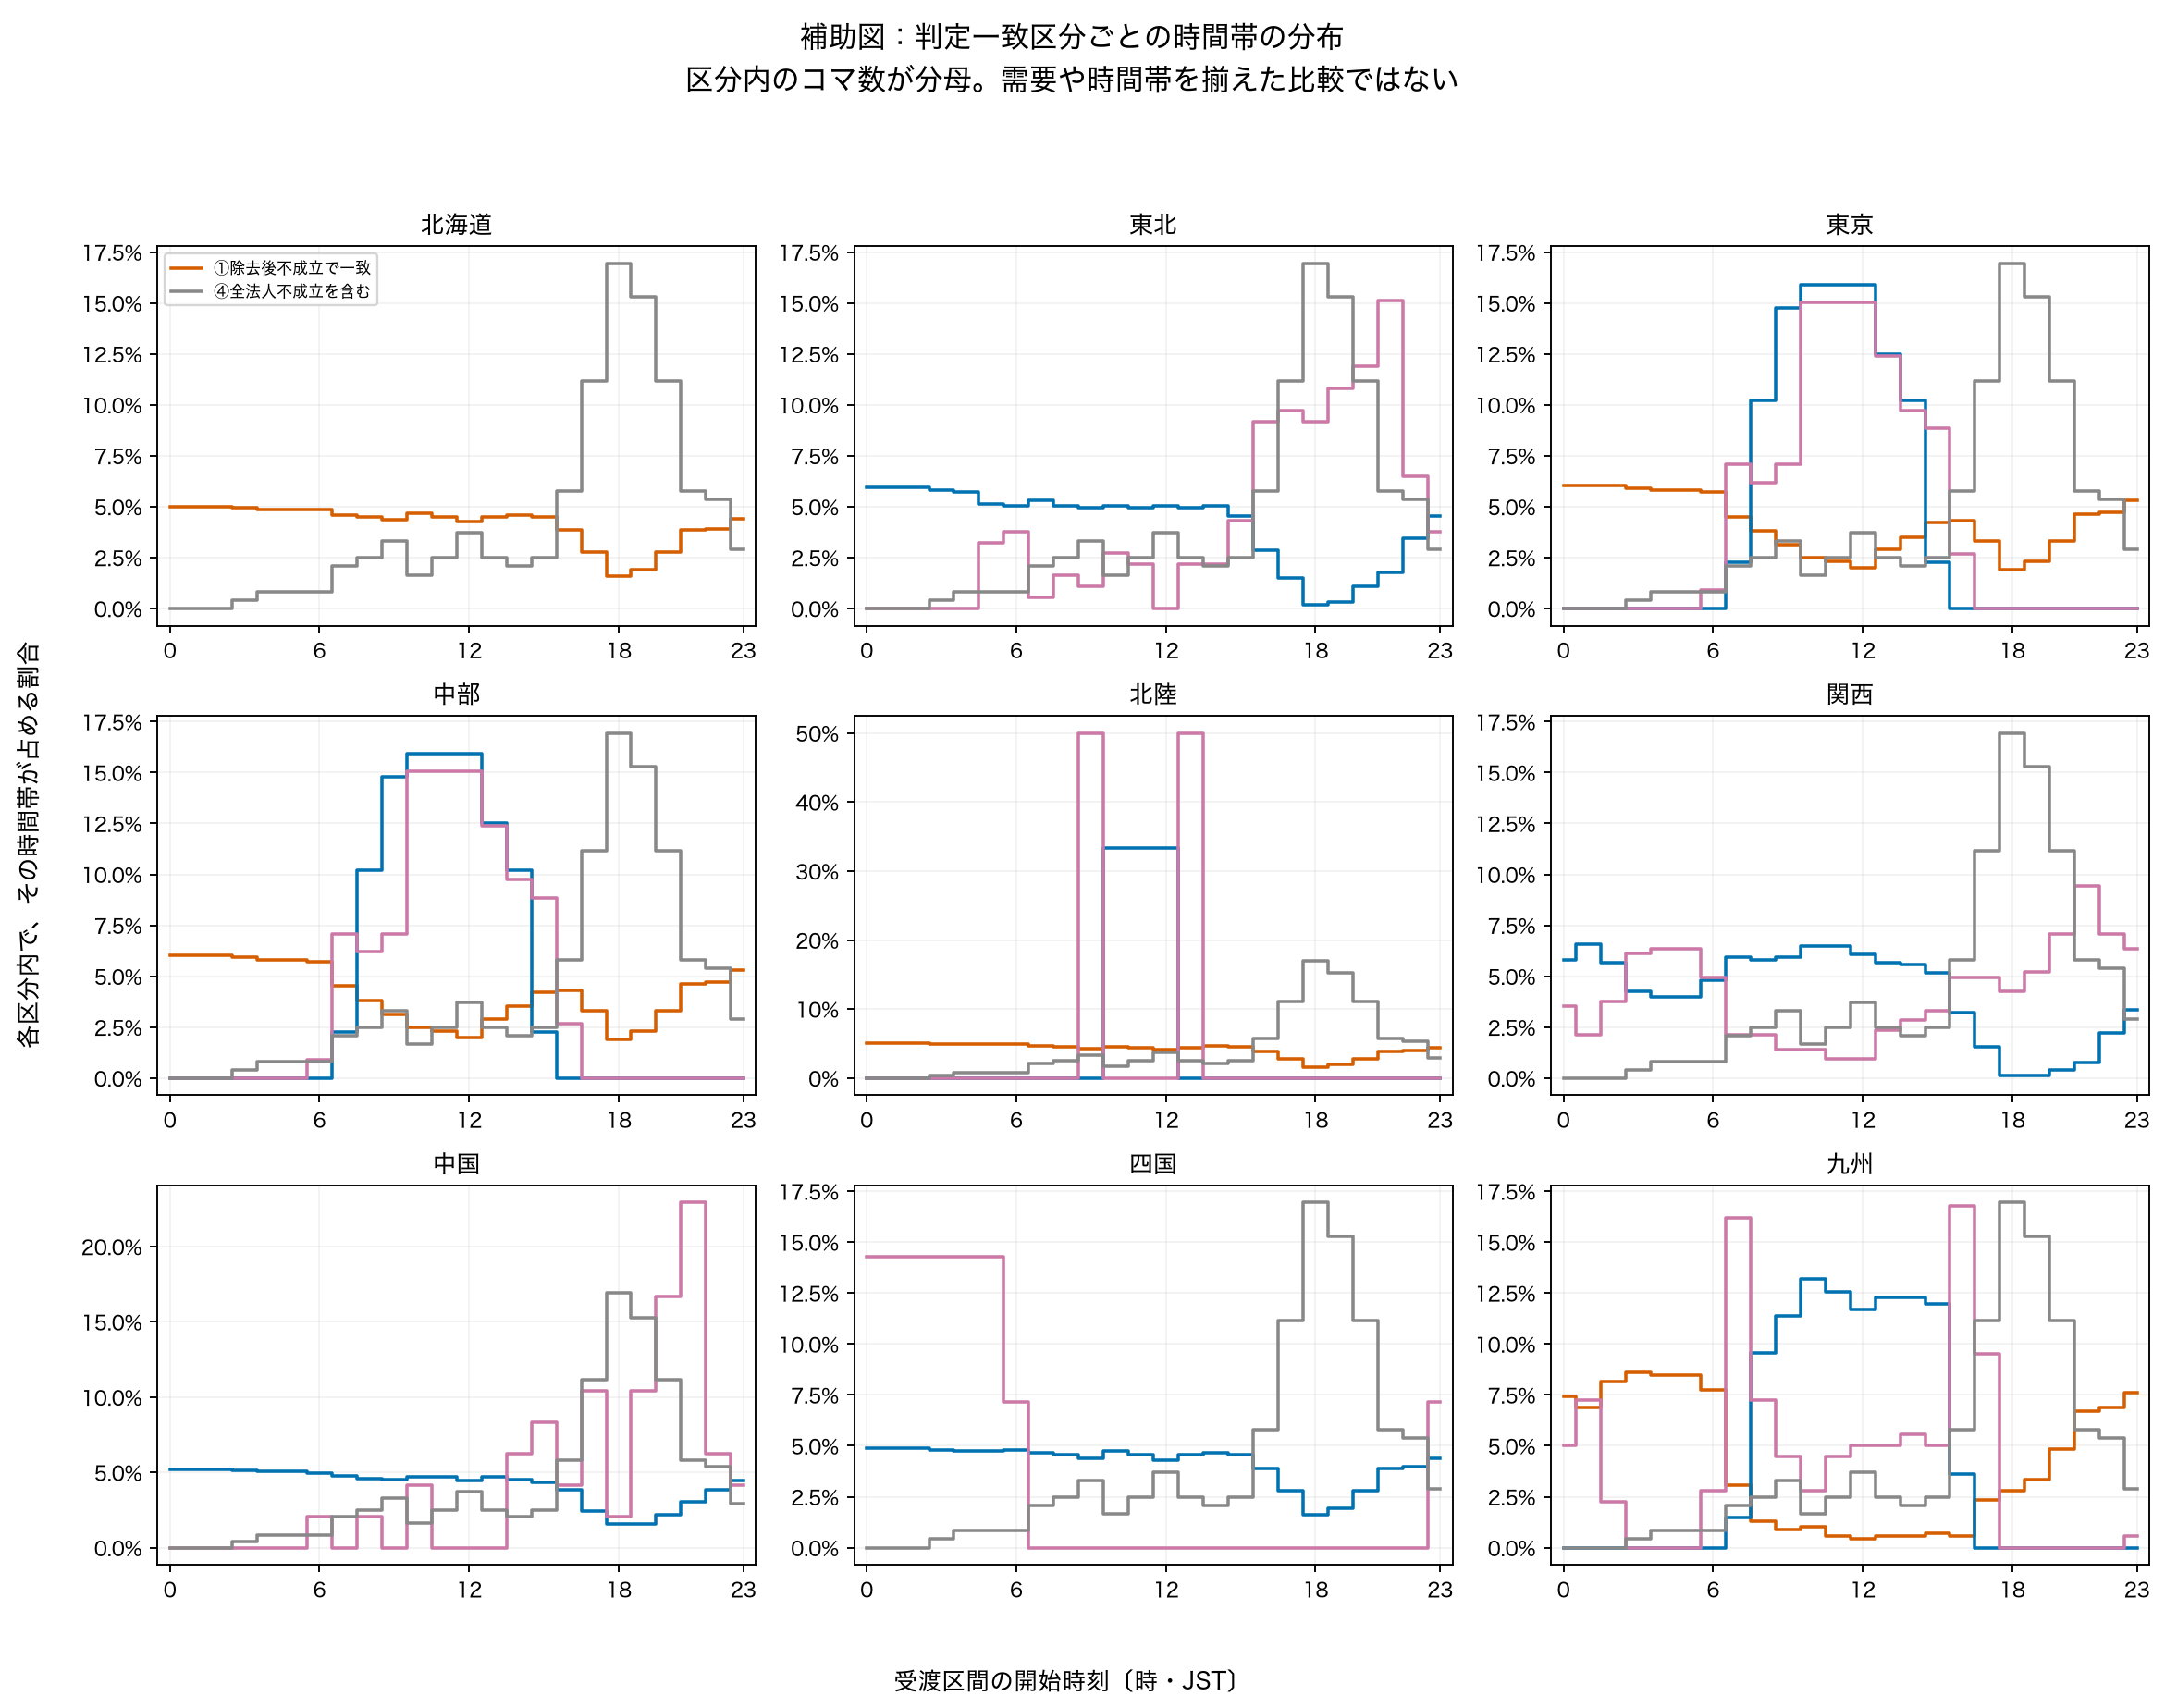

,target_area,consistency_state,variable,count,minimum,q25,median,q75,maximum
1,北海道,all17_base_feasible_removed_infeasible,observed_demand_mw,1198,2563.0,2927.00,3114.5,3322.75,3917.0
2,北海道,all17_base_feasible_removed_infeasible,observed_net_demand_mw,1198,796.0,2073.25,2443.5,2768.00,3431.0
5,北海道,all17_base_feasible_removed_feasible,observed_demand_mw,0,NaN,NaN,NaN,NaN,NaN
6,北海道,all17_base_feasible_removed_feasible,observed_net_demand_mw,0,NaN,NaN,NaN,NaN,NaN
9,北海道,removed_varies_among_baseline_feasible,observed_demand_mw,0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
170,九州,removed_varies_among_baseline_feasible,observed_net_demand_mw,179,430.0,2088.00,2964.0,3446.00,3882.0
173,九州,baseline_scope_differs,observed_demand_mw,242,7056.0,8999.50,9295.0,9725.50,11116.0
174,九州,baseline_scope_differs,observed_net_demand_mw,242,-1532.0,4797.00,5774.0,6262.50,7992.0
177,九州,other_held,observed_demand_mw,0,NaN,NaN,NaN,NaN,NaN


In [7]:
show("04_hour_composition")
display(summary[summary.variable.isin(["observed_demand_mw", "observed_net_demand_mw"])])

## 6．別出力先で再構築する

既定は保存版の閲覧です。Trueにすると既存版を上書きせず、時刻付きの新しい出力先へ接続と描画を再構築します。データ取得や旧LPの再計算は行いません。

In [8]:
REBUILD = False
if REBUILD:
    from datetime import datetime
    from zoneinfo import ZoneInfo

    from scripts.connect_april_prices import run
    from src.april_price_figures import render

    stamp = datetime.now(ZoneInfo("Asia/Tokyo")).strftime("%Y%m%dT%H%M%S")
    new_output = ROOT / "data/interim/occto/april_price_connection" / (stamp + "_reproduction")
    new_report = new_output / "review"
    run(ROOT, new_output, new_report)
    render(new_output, new_report)
    print("再構築先:", new_output)
else:
    import pyarrow.parquet as pq

    for path in sorted(OUT.glob("*.parquet")):
        print(path.name, f"{pq.read_metadata(path).num_rows:,}行")

all_scenarios_with_spot_prices.parquet 440,640行
april_price_observations.parquet 12,960行
consistency_with_prices_by_network.parquet 25,920行
hokkaido_supply_set_reconciliation.parquet 3行
representative_network_original_rows.parquet 22行
